# Module 7: Linear Algebra and the Structure of Markets, Tested on Real Data

*By Héctor Ornelas*

This module changes tools completely. Instead of calculus and random processes, everything is linear
algebra: one period, a few states of the world, and the payoff of each security as a column of a
matrix. With that, questions about markets become questions about rank, kernels and systems of
equations. The course uses a small invented market, and here I build one from real data: three states
defined by the Mexican stock market, and four securities that a person in Mexico can hold. As before, I
take the ten topics of the course in the same order.

The rules are the same as in Module 1: same topics as the course, real data from a Mexican point of
view, and every formula written by hand.

**The market.** One period is one month. The three states are the best, middle and worst third of the
months of the IPC since 2005 ("up", "flat" and "down"). The four securities are the IPC, the SPY
measured in pesos, cash in pesos earning the Mexican 3-month rate, and cash in dollars earning the US
3-month rate, also measured in pesos. Each one costs 1 peso today.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})

prices = pd.read_csv("data/prices.csv", index_col=0, parse_dates=True)
rates = pd.read_csv("data/rates.csv", index_col=0, parse_dates=True)

# month-end prices on days where every series exists
p = prices[["IPC", "SPY", "USDMXN"]].dropna().resample("ME").last()
mx3 = rates["MX3M"].dropna()
mx3.index = mx3.index.to_period("M")
us3 = rates["US3M"].dropna().resample("ME").last()
us3.index = us3.index.to_period("M")
per = p.index.to_period("M")

# gross monthly return of one peso invested in each security (cash earns the rate known at the start)
G = pd.DataFrame({
    "IPC": p["IPC"] / p["IPC"].shift(1),
    "SPY_MXN": (p["SPY"] * p["USDMXN"]) / (p["SPY"] * p["USDMXN"]).shift(1),
    "MX_CASH": 1 + mx3.reindex(per - 1).values / 1200,
    "USD_CASH": p["USDMXN"] / p["USDMXN"].shift(1) * (1 + us3.reindex(per - 1).values / 1200),
}, index=p.index).dropna()

# three states of the world, defined by the IPC: the best, middle and worst third of the months
cut = G["IPC"].quantile([1 / 3, 2 / 3]).values
state = pd.Series(np.where(G["IPC"] <= cut[0], "down", np.where(G["IPC"] <= cut[1], "flat", "up")), index=G.index)
STATES = ["up", "flat", "down"]
print(f"{len(G)} months, {G.index[0]:%b %Y} to {G.index[-1]:%b %Y}")
print(state.value_counts().reindex(STATES).to_string())

260 months, Feb 2005 to Sep 2026
up      87
flat    86
down    87


## 1. A market is a matrix

Each security is described by its **payoff** in each state, and putting them as columns gives the
**payoff matrix** $A$. A **portfolio** is a vector $x$ of amounts held, and its payoff is $Ax$. This is
linear because two pesos in a security pay twice as much as one.

**Exercise 1. The payoff matrix of the Mexican market.** For each state I take the average gross
monthly return of each security, which is what 1 peso became in that kind of month.

In [2]:
# payoff matrix: rows are states, columns are securities, each entry is the average gross return in that state
A_full = G.groupby(state).mean().reindex(STATES)
print("payoff of 1 peso invested, by state (A):")
print(A_full.round(4).to_string())

A = A_full.values
x = np.array([0.5, 0.5, 0.0, 0.0])          # half IPC, half SPY in pesos
print(f"\nportfolio x = {x}  ->  payoff Ax = {A @ x}")

payoff of 1 peso invested, by state (A):
         IPC  SPY_MXN  MX_CASH  USD_CASH
up    1.0569   1.0224   1.0058    0.9903
flat  1.0063   1.0099   1.0054    0.9994
down  0.9585   1.0014   1.0059    1.0218

portfolio x = [0.5 0.5 0.  0. ]  ->  payoff Ax = [1.0397 1.0081 0.98  ]


The matrix already tells a story. The IPC pays 1.057 in "up" months and 0.959 in "down" months, peso
cash pays almost the same 1.005 in every state, and dollar cash does the opposite of the IPC: 0.990 in
"up" months and 1.022 in "down" months, because the peso gets weaker when the Mexican market falls. The
SPY in pesos sits in between, with a payoff that changes much less across states than the IPC. A
portfolio of half IPC and half SPY pays 1.040, 1.008 and 0.980, which is just $Ax$.

## 2. Complete, incomplete and overcomplete markets

The basic question goes backwards: for a payoff $b$ that I want, is there a portfolio $x$ with
$Ax = b$? The answer depends on the rank. If $\mathrm{rank}(A)$ equals the number of states, the market
is **complete** and every payoff can be built. If it is smaller, the market is **incomplete**.

**Exercise 2. Can I build crash insurance?** The payoff I want is 1 peso in a "down" month and nothing
otherwise. I try with the four securities and with only the IPC and peso cash.

In [3]:
print(f"rank with all four securities  : {np.linalg.matrix_rank(A)}  (3 states)")
A2 = A_full[["IPC", "MX_CASH"]].values
print(f"rank with only IPC and MX cash  : {np.linalg.matrix_rank(A2)}")

b = np.array([0.0, 0.0, 1.0])               # a payoff of 1 peso only in a "down" month: crash insurance
for name, M in [("all four securities", A), ("IPC and MX cash only", A2)]:
    xs, *_ = np.linalg.lstsq(M, b, rcond=None)
    print(f"\n{name}: best portfolio {xs.round(2)}  ->  payoff {(M @ xs).round(3)}  (target {b})")

rank with all four securities  : 3  (3 states)
rank with only IPC and MX cash  : 2

all four securities: best portfolio [ 19.58 -18.32 -81.8   81.09]  ->  payoff [0. 0. 1.]  (target [0. 0. 1.])

IPC and MX cash only: best portfolio [-10.09  10.44]  ->  payoff [-0.166  0.34   0.827]  (target [0. 0. 1.])


With the four securities the rank is 3, the market is complete, and the insurance can be built exactly.
With only the IPC and peso cash the rank is 2, and the best possible portfolio pays $-0.17$, 0.34 and
0.83 instead of 0, 0 and 1. So for a person who only has access to the Mexican market and to pesos,
protection against a bad month for Mexico cannot be built, and adding the dollar is what completes the
market. However, look at the portfolio that builds it: 19.6 pesos in the IPC, $-18.3$ in the SPY in
pesos, $-81.8$ in peso cash and 81.1 in dollar cash for every peso of insurance. That is a first warning, which Section 4 explains.

## 3. Redundancy and the kernel

With four securities and three states, at least one security is redundant. In algebra, the **kernel**
of $A$ is not empty: there is a portfolio $z \neq 0$ with $Az = 0$, a combination that pays nothing in
any state. If $Ax = b$, then $A(x + cz) = b$ for any $c$, so many portfolios give the same payoff.

**Exercise 3. The portfolio that pays nothing.** I find the kernel of $A$ with the singular value
decomposition, and then I check what this portfolio really paid month by month.

In [4]:
# kernel of A: portfolios with zero payoff in every state (from the SVD, the direction with zero singular value)
_, s, Vt = np.linalg.svd(A)
z = Vt[-1]
z = z / np.abs(z).max()
print(f"singular values: {s.round(5)}")
print(f"kernel portfolio z = {dict(zip(A_full.columns, z.round(3)))}")
print(f"payoff Az = {(A @ z).round(6)}")

# in the model it pays nothing; month by month it does not
real = (G.values - 1) @ z + z.sum()          # payoff of the z portfolio in each real month
print(f"\nreal monthly payoff of z: mean {real.mean():+.4f}   std {real.std():.4f}")
print(f"for comparison, std of the IPC monthly return: {G['IPC'].std():.4f}")

singular values: [3.4885 0.0677 0.0033]
kernel portfolio z = {'IPC': np.float64(0.283), 'SPY_MXN': np.float64(-1.0), 'MX_CASH': np.float64(0.506), 'USD_CASH': np.float64(0.216)}
payoff Az = [ 0. -0.  0.]

real monthly payoff of z: mean +0.0000   std 0.0334
for comparison, std of the IPC monthly return: 0.0469


The kernel portfolio is long 0.28 in the IPC, short 1 in the SPY in pesos, and long 0.51 in peso cash and
0.22 in dollar cash, and in the model it pays exactly zero in every state. In the real months it does
not: its payoff has a standard deviation of 3.3% per month, not far from the 4.7% of the IPC itself.
The reason is that the model uses the average payoff of each state, and inside each state the real
returns are very spread out. Three states are a big simplification of what can happen in a month.

## 4. Arrow-Debreu securities: the natural basis

In a complete market with a square, invertible $A$, the most useful securities are the ones that pay 1
in one state and nothing in the others, the **Arrow-Debreu securities**. They are not traded, but they
can be built as portfolios: $x_i = A^{-1}e_i$.

**Exercise 4. The three Arrow-Debreu securities.** I use the IPC, peso cash and dollar cash, invert the
matrix, and check the "down" security with the real months.

In [5]:
# a square, invertible market: IPC, peso cash and dollar cash
sec3 = ["IPC", "MX_CASH", "USD_CASH"]
A3 = A_full[sec3].values
AD = np.linalg.inv(A3)                       # column i = portfolio that pays 1 only in state i
print("Arrow-Debreu portfolios (rows = securities, columns = state where it pays 1):")
print(pd.DataFrame(AD, index=sec3, columns=STATES).round(2).to_string())

# check the "down" security with the real months
down_port = AD[:, 2]
real = G[sec3].values @ down_port
print("\nreal payoff of the 'down' Arrow-Debreu portfolio, by state:")
print(pd.Series(real, index=G.index).groupby(state).agg(["mean", "std"]).reindex(STATES).round(3).to_string())

Arrow-Debreu portfolios (rows = securities, columns = state where it pays 1):
              up    flat   down
IPC        33.74  -48.15  14.39
MX_CASH  -107.39  199.54 -91.07
USD_CASH   74.07 -151.26  77.13

real payoff of the 'down' Arrow-Debreu portfolio, by state:
      mean    std
up     0.0  1.870
flat  -0.0  1.945
down   1.0  2.802


The portfolios are enormous. To get 1 peso only in a "down" month, the model needs 14.4 pesos in the
IPC, $-91.1$ in peso cash and 77.1 in dollar cash, and the "flat" security is even larger, with 199.5
pesos in peso cash. On average it works, it pays exactly 0, 0 and 1. But
month by month its payoff has a standard deviation between 1.9 and 2.8 pesos, so a security that should
pay 1 peso in a bad month can easily pay 3 or lose 2. This happens because peso cash and dollar cash
look very similar in the matrix, so separating the states needs huge long and short positions. In
practice, real insurance against a bad month is bought as an option, not built like this.

## 5. State prices and the pricing relationship

The prices of the Arrow-Debreu securities are the **state prices** $\psi_i$: what it costs today to get
1 peso in state $i$. If every security costs 1 peso today, the prices satisfy $S = A^{\top}\psi$, so the
state prices come from solving a linear system.

**Exercise 5. The state prices of the Mexican market.** I solve $A^{\top}\psi = S$ for the three
securities, and then repeat it with each half of the history to see how stable the answer is.

In [6]:
S3 = np.ones(3)                              # each security costs 1 peso today
psi = np.linalg.solve(A3.T, S3)              # S = A^T psi
print(f"state prices psi (up, flat, down): {psi.round(4)}")
print(f"sum of state prices: {psi.sum():.4f}   ->  one-month discount factor")
print(f"average MX cash return: {A_full['MX_CASH'].mean():.4f}   ->  1 / that = {1 / A_full['MX_CASH'].mean():.4f}")

# how stable are they? the same calculation with each half of the history
print(f"\ncondition number of A: {np.linalg.cond(A3):,.0f}")
half = len(G) // 2
for name, idx in [("first half", G.index[:half]), ("second half", G.index[half:])]:
    Ah = G.loc[idx, sec3].groupby(state.loc[idx]).mean().reindex(STATES).values
    print(f"{name:<12} psi = {np.linalg.solve(Ah.T, S3).round(3)}")

state prices psi (up, flat, down): [0.4165 0.126  0.4518]
sum of state prices: 0.9943   ->  one-month discount factor
average MX cash return: 1.0057   ->  1 / that = 0.9943

condition number of A: 942
first half   psi = [0.199 0.542 0.254]
second half  psi = [ 0.6   -0.195  0.588]


The state prices are 0.417 for "up", 0.126 for "flat" and 0.452 for "down", all positive, and they add
up to 0.9943, the price of 1 peso in a month at the Mexican cash rate. This last match is a check that
the calculation is right more than a finding: peso cash is one of the three securities, it costs 1 peso
and pays almost the same in every state, so the sum has to come out close to its discount factor. The
part that tells something is how the total splits between the states, and that is not stable.
With the first half of the history, the "flat" state is the most expensive (0.542), and with the second
half its price is negative. The condition number of the matrix is 942, which means that small changes
in the averages become large changes in $\psi$. So the method is correct, but state prices estimated
from historical averages are not reliable.

## 6. Two kinds of arbitrage

**Type I:** a portfolio that costs nothing or less today and pays something positive in at least one
state and nothing negative in any. **Type II:** a portfolio that pays zero in every state but has a
non-zero price, so it can be sold for money and never pays anything.

**Exercise 6. Looking for arbitrage in the model.** I check the price of the kernel portfolio from
Section 3, and I check if any security pays more than another in every state.

In [7]:
# with all four securities, the kernel portfolio z pays nothing in the model; what does it cost?
S = np.ones(4)
print(f"price of z = S . z = {S @ z:+.4f}")
print("a non-zero price for a zero payoff is a type II arbitrage, inside the model")

# dominance: does any security pay more than another in every state? (type I)
cols = list(A_full.columns)
found = False
for i in range(4):
    for j in range(4):
        if i != j and np.all(A[:, i] > A[:, j]):
            print(f"{cols[i]} pays more than {cols[j]} in every state, at the same price")
            found = True
if not found:
    print("no security pays more than another in every state, so there is no type I arbitrage by dominance")

price of z = S . z = +0.0055
a non-zero price for a zero payoff is a type II arbitrage, inside the model
no security pays more than another in every state, so there is no type I arbitrage by dominance


No security pays more than another in every state, so there is no simple type I arbitrage. But the
kernel portfolio pays zero in every state of the model and costs 0.0055 pesos, which is a type II
arbitrage: in the model, selling it gives free money. In reality it is not free at all, because
Section 3 showed that this portfolio has a monthly risk of 3.3%. An "arbitrage" of half a cent with that
much risk is just a sign that the model is too simple.

## 7. The Fundamental Theorem of Asset Pricing

The central result of the module: there is **no arbitrage** if and only if there is a **strictly
positive** state price vector $\psi$ with $S = A^{\top}\psi$.

**Exercise 7. Testing the theorem in both markets.** With three securities and with four, I look for
the $\psi$ that best matches the prices and check if it is positive and exact.

In [8]:
for name, M in [("three securities (IPC, MX cash, USD cash)", A3), ("all four securities", A)]:
    n = M.shape[1]
    psi_ls, *_ = np.linalg.lstsq(M.T, np.ones(n), rcond=None)
    gap = np.abs(M.T @ psi_ls - np.ones(n)).max()
    print(f"{name}:")
    print(f"   best psi {psi_ls.round(4)}   largest pricing gap {gap:.5f}   all positive: {np.all(psi_ls > 0)}")

three securities (IPC, MX cash, USD cash):
   best psi [0.4165 0.126  0.4518]   largest pricing gap 0.00000   all positive: True
all four securities:
   best psi [ 0.531  -0.0915  0.5527]   largest pricing gap 0.00398   all positive: False


With three securities, $\psi$ matches the prices exactly and is positive, so the model has no
arbitrage. With four securities there is no exact solution, the best $\psi$ leaves a pricing gap of
0.004 and has a negative price for the "flat" state. This is the theorem working: the type II arbitrage
of Section 6 and the absence of a positive $\psi$ are the same fact. Adding a fourth real security to a
three-state model is enough to create an arbitrage that does not exist in the real market.

## 8. Incomplete markets: many state prices at once

In an incomplete market there are fewer prices than state prices, so $S = A^{\top}\psi$ has infinitely
many solutions: one particular solution plus any multiple of a kernel direction. Requiring all state
prices to be positive keeps only a segment of that line.

**Exercise 8. A market with only the IPC and peso cash.** I find the line of solutions and the segment
where every state price is positive.

In [9]:
# only IPC and MX cash: two prices, three state prices -> a line of solutions psi_p + c k
S2 = np.ones(2)
psi_p, *_ = np.linalg.lstsq(A2.T, S2, rcond=None)
k = np.linalg.svd(A2.T)[2][-1]               # kernel of A2^T
# keep only the c where every state price is positive
lo, hi = -np.inf, np.inf
for pi_, ki in zip(psi_p, k):
    if ki > 0:
        lo = max(lo, -pi_ / ki)
    elif ki < 0:
        hi = min(hi, -pi_ / ki)
print(f"particular solution {psi_p.round(4)}   kernel direction {k.round(4)}")
print(f"positive state prices for c in ({lo:.4f}, {hi:.4f})")

particular solution [0.3158 0.3316 0.347 ]   kernel direction [ 0.3998 -0.8165  0.4164]
positive state prices for c in (-0.7898, 0.4061)


Every $\psi = \psi_p + c\,k$ with $c$ between $-0.790$ and $0.406$ is a valid set of positive state
prices. So the market of a person who only holds the IPC and pesos has no arbitrage, but it also does not
have unique state prices: many different values for "how much is 1 peso in a bad month worth" are
consistent with what is traded.

## 9. What incompleteness costs: bounds instead of prices

If many $\psi$ are possible, a payoff that cannot be built gets a range of prices instead of one price.
A payoff that can be built gets the same price from every admissible $\psi$.

**Exercise 9. The price of crash insurance with and without dollars.** I compute the price of 1 peso in
a "down" month for every admissible $\psi$ of the incomplete market, and compare it with the complete
market that includes dollar cash.

In [10]:
cs = np.linspace(lo, hi, 2001)[1:-1]
psis = np.array([psi_p + c * k for c in cs])
ins = psis[:, 2]                              # price of 1 peso paid only in a "down" month
cash_like = psis @ A_full["MX_CASH"].values   # price of the MX cash payoff, which can be replicated
print(f"incomplete market (IPC + MX cash):")
print(f"   crash insurance: any price between {ins.min():.4f} and {ins.max():.4f}")
print(f"   MX cash payoff : {cash_like.min():.4f} to {cash_like.max():.4f}  (replicable, so one price)")
print(f"complete market (add USD cash): crash insurance costs exactly {psi[2]:.4f}")

incomplete market (IPC + MX cash):
   crash insurance: any price between 0.0184 and 0.5158
   MX cash payoff : 1.0000 to 1.0000  (replicable, so one price)
complete market (add USD cash): crash insurance costs exactly 0.4518


Without dollars, crash insurance can have any price between 0.018 and 0.516 pesos, a range so wide that
it says almost nothing. The payoff of peso cash, which can be built, has one price, exactly 1. Adding
dollar cash completes the market and fixes the price of the insurance at 0.452. So for a Mexican, the
dollar is not only an asset, it is what makes the price of protection against a bad month for Mexico
well defined, even if Section 5 showed that the exact number depends a lot on the data used.

## 10. Risk-neutral probabilities, derived from scratch

State prices are positive but do not add up to 1. Their sum is the price of 1 peso in every state,
which is the discount factor. Dividing by it gives probabilities:

$$q_i = \frac{\psi_i}{\sum_j \psi_j}, \qquad \text{price} = \Big(\sum_j \psi_j\Big)\, \mathbb{E}^{Q}[\text{payoff}].$$

These are the **risk-neutral probabilities** of Modules 5 and 6, and here they come only from prices.

**Exercise 10. Real against risk-neutral.** I compare the real frequency of each state, one third each
by construction, with the risk-neutral probabilities of the complete market.

state   real frequency  risk-neutral q
up               0.335           0.419
flat             0.331           0.127
down             0.335           0.454

risk-neutral q by half of the history (up, flat, down):
  first half   q = [0.2   0.545 0.255]
  second half  q = [ 0.604 -0.196  0.592]


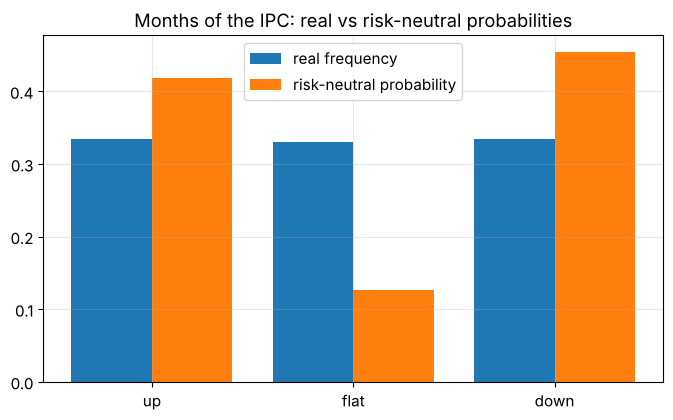

In [11]:
q = psi / psi.sum()
freq = state.value_counts(normalize=True).reindex(STATES).values
print(f"{'state':<6}{'real frequency':>16}{'risk-neutral q':>16}")
for s_, f, qq in zip(STATES, freq, q):
    print(f"{s_:<6}{f:>16.3f}{qq:>16.3f}")

# the same risk-neutral probabilities with each half of the history (Section 5 showed psi is unstable)
print("\nrisk-neutral q by half of the history (up, flat, down):")
for name, idx in [("first half", G.index[:half]), ("second half", G.index[half:])]:
    Ah = G.loc[idx, sec3].groupby(state.loc[idx]).mean().reindex(STATES).values
    ph = np.linalg.solve(Ah.T, S3)
    print(f"  {name:<12} q = {(ph / ph.sum()).round(3)}")

plt.bar(np.arange(3) - 0.2, freq, width=0.4, label="real frequency")
plt.bar(np.arange(3) + 0.2, q, width=0.4, label="risk-neutral probability")
plt.xticks(range(3), STATES); plt.title("Months of the IPC: real vs risk-neutral probabilities")
plt.legend(); plt.show()

The real frequency of each state is one third, but the risk-neutral probability of a "down" month is
0.454 and of an "up" month 0.419. The theory says that bad months should weigh more under $Q$, because
protection against them is expensive, and Module 6 found that with the SPY. Here the data cannot confirm
it. The gap between "down" and "up" is small, and with each half of the history the answer changes
completely: with the first half the "down" state gets 0.255, less than its real frequency, and with the
second half it gets 0.592, while the "flat" state gets a negative number. So the method gives
risk-neutral probabilities from prices, but with three average states estimated from 21 years they are
too unstable to say which kind of month the market weighs more.

## Wrapping up Module 7

Writing a market as a matrix turns finance into linear algebra, and the real Mexican market shows both
the power and the limits of the idea. The rank shows that a person with only the IPC and pesos cannot
build protection against a bad month for Mexico, and that adding dollar cash completes the market. The
state prices add up to the discount factor of peso cash, and dividing by it turns them into risk-neutral
probabilities.

The limits are just as clear. Three states are too few to describe a real month, so the kernel
portfolio that "pays nothing" has a risk of 3.3% per month, the Arrow-Debreu securities need positions of
up to 200 times the payoff, and the state prices and risk-neutral probabilities change completely between
the two halves of the history.
The theory of this module is exact, but the matrix it needs cannot be estimated precisely from 21 years
of averages.

The next step is Module 8, which moves from what a market can do to which portfolio a person should
hold.